# Atera 空间转录组 — 官方 Zarr + 单分子点云

[Atera](https://www.10xgenomics.com/support/instruments/atera) 是 10x 的新一代空间平台。
本 notebook 演示 `trackcell` 对 Atera 的完整支持：

1. **元信息检查**：不加载矩阵，先看清 bundle 里有什么
2. **官方 Zarr 读取**：AnnData Zarr + `cells.zarr` 多边形
3. **统一 schema**：gene symbol / gene ID / feature type / 控制探针
4. **细胞级 QC** 与空间可视化
5. **单分子点云**：Q-score、转录本密度、核质定位
6. **preview bundle**：与官方数据同一套 API

> **数据准备**：设置环境变量 `ATERA_DATA` 指向包含
> `kidney_official/` 和 `cervical_preview/` 的目录。
> 数据可从 10x 官网下载：
> [kidney WTA](https://www.10xgenomics.com/datasets/atera-wta-ffpe-human-nd-kidney)。
>
> 官方 `centroid_column/row` 单位已经是 **µm**；`pixel_size` 只用于 morphology 图像。

In [1]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import trackcell as tcl

DATA_DIR = Path(os.environ.get("ATERA_DATA", ".")).expanduser()
ROI = DATA_DIR / "kidney_official"
PREVIEW = DATA_DIR / "cervical_preview"

plt.rcParams["figure.dpi"] = 110
print("trackcell", tcl.__version__)
print("data dir :", DATA_DIR)

trackcell 0.3.43
data dir : <ATERA_DATA>


## 1. 先看元信息，再决定怎么读

`atera_info()` 只读 Zarr 元数据和属性，不加载 600M 非零的矩阵，
几秒钟就能告诉你：细胞数、基因数、Gene Expression 探针数、
多边形覆盖率、转录本总数和软件版本。

In [2]:
info = tcl.io.atera_info(ROI)

[Atera] <ATERA_DATA>/kidney_official
  format          : cellseg
  roi/slide/run   : S2B_kidney_ND / S2 / WTA_FFPE_Dataset
  cells × features: 399,120 × 24,674 (18,049 Gene Expression)
  polygons        : 399,120 cell / 398,197 nucleus
  transcripts     : 1,186,813,834 molecules, 30 grid tiles, 2000 µm/tile
  coord unit      : µm (pixel_size=0.21249222, z_step=3.0)
  software        : chemistry=Atera v1, analysis=atera-1.0.4.1


In [3]:
# 一个 run 目录下每个 ROI 是一个独立 bundle
tcl.io.list_atera_rois(DATA_DIR)

,roi,path,format,n_cells,n_features,n_gene_expression,has_transcripts,number_rnas
0,WTA Breast Cancer (FFPE),/Volumes/data/co_project/RD/atera/data/breast_...,preview,170057,27104,18028,False,NaN
1,WTA Cervical Cancer (FFPE),/Volumes/data/co_project/RD/atera/data/cervica...,preview,717576,27104,18028,False,NaN
2,S2B_kidney_ND,/Volumes/data/co_project/RD/atera/data/kidney_...,cellseg,399120,24674,18049,True,1.186814e+09


## 2. 读取官方 Zarr（按区域取子集）

`region` 使用 `(xmin, ymin, xmax, ymax)`，单位 µm。
细胞先按 centroid 过滤，再只构建选中细胞的多边形。

In [4]:
adata = tcl.io.read_atera(
    ROI,
    region=(700, 1900, 1100, 2300),   # xmin, ymin, xmax, ymax (µm)
    build_polygons=True,
    include_nucleus=True,
    store_wkt=False,
)
adata

[Atera] Matrix: 399,120 cells × 24,674 features (599.2M non-zero) [2.5s]
[Atera] Features: 24,674 total, 18,049 Gene Expression (use `tcl.io.filter_atera_genes(adata)` before HVG/PCA)
[Atera] Subset to 1,246 cells


[Atera] geometries: 1,245 polygons (99.9% of cells)


[Atera] nucleus_geometries: 1,227 polygons (98.5% of cells)
[Atera] Polygons built [33.3s]
[Atera] Total: read_atera_cellseg done [36.0s]


AnnData object with n_obs × n_vars = 1246 × 24674
    obs: 'barcode', 'cell_id', 'filtered', 'leiden_res_1.0', 'centroid_column', 'centroid_row', 'cell_area', 'nucleus_area', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'azimuth_broad', 'azimuth_coarse', 'azimuth_fine', 'azimuth_score', 'azimuth_full_hierarchy', 'cell_prefix', 'dataset_suffix'
    var: 'feature_name', 'filtered', 'highly_variable', 'feature_id', 'feature_type', 'genome', 'gene_ids', 'feature_types', 'is_gene_expression'
    uns: 'experiment', 'atera', 'spatial', 'cell_boundaries', 'nucleus_boundaries'
    obsm: 'X_pca', 'X_umap', 'spatial'

### 统一的 AnnData schema

两种 Atera 格式（official / preview）读出来结构一致：

| 位置 | 内容 |
|---|---|
| `var_names` | gene symbol（`gene_name_index=True`） |
| `var['gene_ids']` | Ensembl ID |
| `var['feature_types']` | Gene Expression / Negative Control Codeword / ... |
| `var['is_gene_expression']` | 布尔掩码，PCA 前用它过滤控制探针 |
| `obs['barcode']` / `obs_names` | 字符串 barcode |
| `obs['cell_id']` / `cell_prefix` | 官方 uint32 ID / 点云 mapping key |
| `obsm['spatial']` | x, y（µm） |
| `uns['spatial'][sample]['geometries']` | 细胞多边形（GeoDataFrame） |

In [5]:
print("var_names     :", adata.var_names[:5].tolist())
print("gene_ids      :", adata.var["gene_ids"][:3].tolist())
print("feature types :", adata.var["feature_types"].value_counts().to_dict())
print("cell_prefix   :", adata.obs["cell_prefix"][:5].tolist())
print("coord unit    :", adata.uns["atera"]["coord_unit"])
print("pixel size    :", adata.uns["atera"]["pixel_size"])
print("polygons      :", len(adata.uns["spatial"][adata.uns["atera"]["sample"]]["geometries"]))

var_names     : ['A1BG', 'A1CF', 'A2M', 'A2ML1', 'A3GALT2']
gene_ids      : ['ENSG00000121410', 'ENSG00000148584', 'ENSG00000175899']
feature types : {'Gene Expression': 18049, 'Negative Control Codeword': 6390, 'Unassigned Codeword': 91, 'Negative Control Probe': 81, 'Genomic Control': 61, 'Deprecated Codeword': 2}
cell_prefix   : [25465, 35945, 37135, 38950, 42008]
coord unit    : um
pixel size    : 0.21249222
polygons      : 1245


## 3. 细胞多边形空间图

`tcl.pl.spatial_cell()` 直接使用 `uns['spatial'][sample]['geometries']`，
不需要 `obs['geometry']`（WKT 是可选的，用 `add_wkt_geometry()` 按需添加）。

trackcell/pl/plot.py:350: UserWarning: 1 observations have no stored geometry and will be skipped. Examples: ['nmemoepm-1']
  warnings.warn(


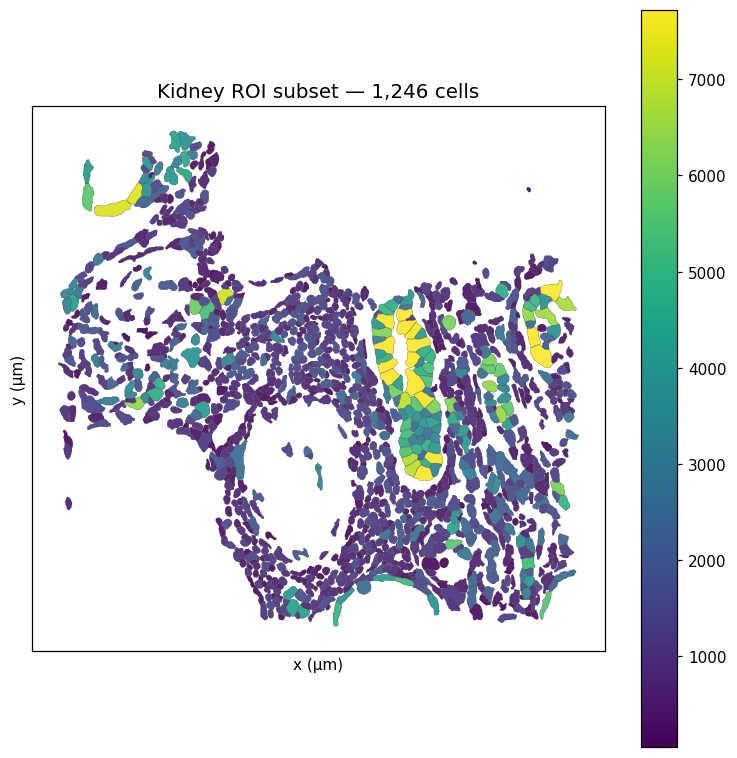

In [6]:
fig, ax = plt.subplots(figsize=(7, 7))
tcl.pl.spatial_cell(
    adata,
    color="total_counts",
    cmap="viridis",
    edges_width=0.15,
    alpha=0.9,
    legend=True,
    show=False,
    ax=ax,
    figsize=None,
    vmin=np.percentile(adata.obs["total_counts"], 1),
    vmax=np.percentile(adata.obs["total_counts"], 99),
    xlabel="x (µm)",
    ylabel="y (µm)",
)
ax.set_title(f"Kidney ROI subset — {adata.n_obs:,} cells", fontsize=13)
plt.tight_layout()

# thumbnail for the documentation gallery
Path("../_static/notebooks").mkdir(parents=True, exist_ok=True)
fig.savefig("../_static/notebooks/Atera_demo.png", dpi=110, bbox_inches="tight")
plt.show()

## 4. 细胞级 QC

`atera_cell_qc()` 只读 `obs` / `X`，不触碰点云：

* `total_counts` 包含 control 探针；做基因表达 QC 请用 `transcript_counts`
* `n_genes_expression` 只统计 `feature_type == "Gene Expression"`
* 另外给出细胞面积、核面积、control fraction

In [7]:
full = tcl.io.read_atera(ROI, build_polygons=False, verbose=False)
qc = tcl.io.atera_cell_qc(full)

qc.describe().loc[["mean", "50%", "max"]].round(2)

,total_counts,transcript_counts,n_genes,n_genes_expression,cell_area,nucleus_area,nuclear_area_ratio,control_counts,control_fraction
mean,2288.49,2288.17,1501.33,1501.07,60.77,25.25,0.47,0.16,0.00
50%,1595.00,1595.00,1221.00,1220.00,49.94,23.61,0.48,0.00,0.00
max,25521.00,25518.00,7655.00,7653.00,663.34,224.91,1.00,8.00,0.12


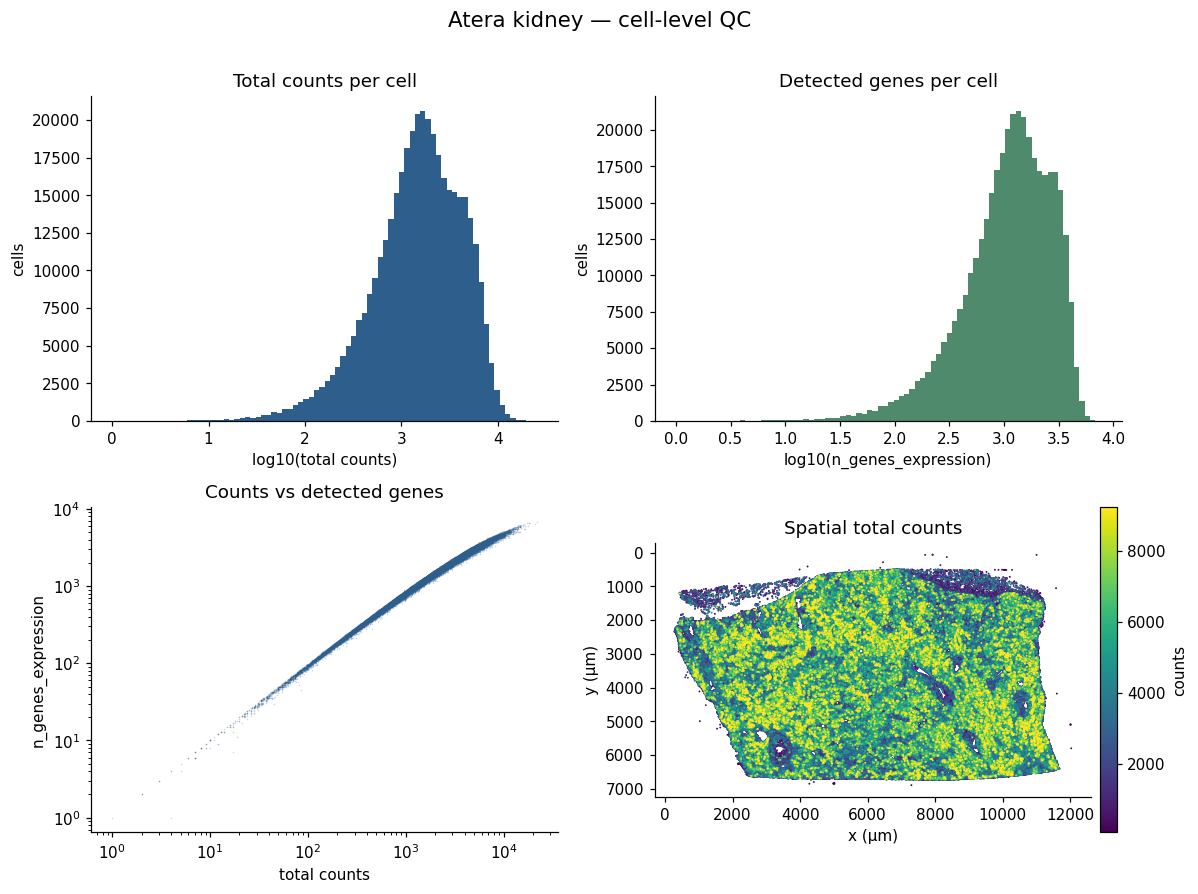

In [8]:
axes = tcl.pl.atera_qc_summary(full, qc=qc, show=False)
axes[0].figure.suptitle("Atera kidney — cell-level QC", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 5. 单分子点云 QC

`transcripts.zarr.zip` 里有约 **11.9 亿** 个分子，不能一次性读进内存。
`atera_transcript_qc()` 按 grid tile + chunk 流式扫描，并把结果写回 `adata`：

* `obs['tx_q20_counts']` / `tx_nuclear_counts` / `nuclear_fraction`
* `uns['atera']['qscore']`：Q-score 直方图
* `uns['atera']['density']`：二维转录本密度
* `uns['atera']['gene_qc']`：每个基因的总数 / 核内数 / 核内比例

全量扫描约 5 分钟（kidney，1.19B molecules）。

In [9]:
summary = tcl.io.atera_transcript_qc(
    ROI, adata=full, min_qv=20, bins=120, verbose=False
)
pd.Series(summary).to_frame("value")

,value
number_rnas,1.186814e+09
read,1.186814e+09
min_qv,2.000000e+01
q20,1.083912e+09
q20_fraction,9.132953e-01
assigned_q20,9.133513e+08
assigned_fraction_q20,8.426438e-01
overall_nuclear_fraction,5.706137e-01
cells_with_transcripts,3.991010e+05
n_cells,3.991200e+05


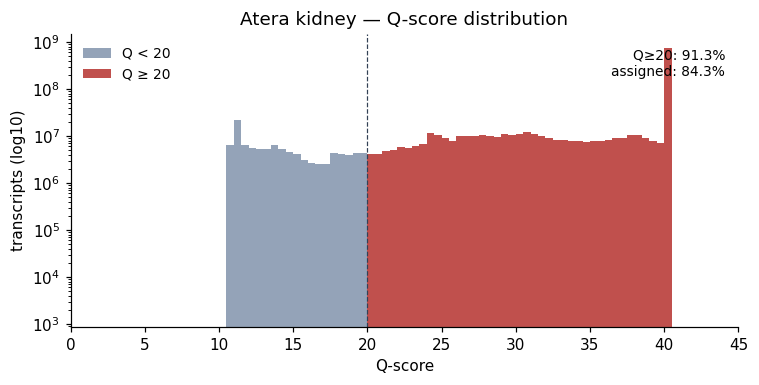

In [10]:
q = full.uns["atera"]["qscore"]
centers, total, hq = q["centers"], q["total"], q["hq"]

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(centers, total - hq, width=0.5, color="#94A3B8", label="Q < 20")
ax.bar(centers, hq, bottom=total - hq, width=0.5, color="#C0504D", label="Q ≥ 20")
ax.axvline(20, color="#334155", ls="--", lw=0.8)
ax.set_yscale("log")
ax.set_xlim(0, 45)
ax.set_xlabel("Q-score")
ax.set_ylabel("transcripts (log10)")
ax.set_title("Atera kidney — Q-score distribution")
ax.text(
    0.98, 0.95,
    f"Q≥20: {summary['q20_fraction'] * 100:.1f}%\n"
    f"assigned: {summary['assigned_fraction_q20'] * 100:.1f}%",
    transform=ax.transAxes, ha="right", va="top", fontsize=9,
)
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 6. 转录本空间密度

密度图由 `atera_transcript_qc()` 计算并存入 `uns['atera']['density']`，
绘图函数只读 `adata`，可以反复调用。

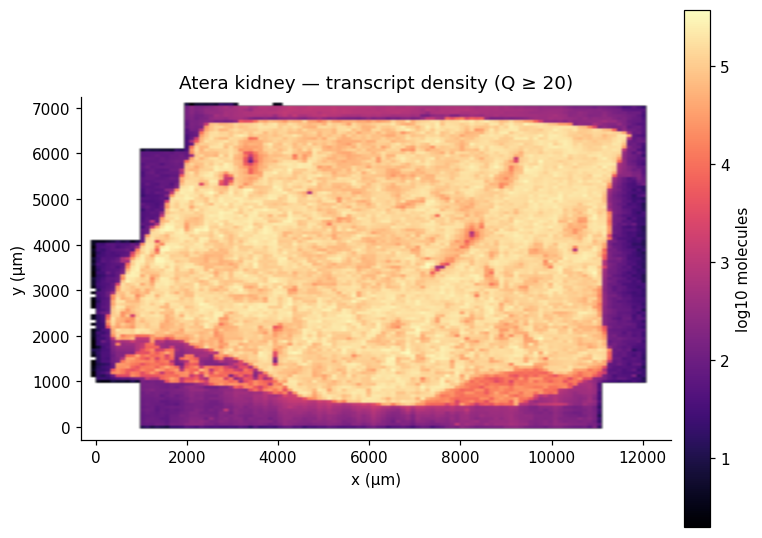

In [11]:
ax = tcl.pl.atera_transcript_density(full, show=False)
ax.set_title("Atera kidney — transcript density (Q ≥ 20)")
plt.tight_layout()
plt.show()

## 7. 核质定位

`overlaps_nucleus` 是分子是否落在细胞核 mask 内的标记。
它 **不是** unspliced 计数，不能用于 RNA velocity。

按基因统计核内比例可以区分胞质/分泌基因与核内转录因子。

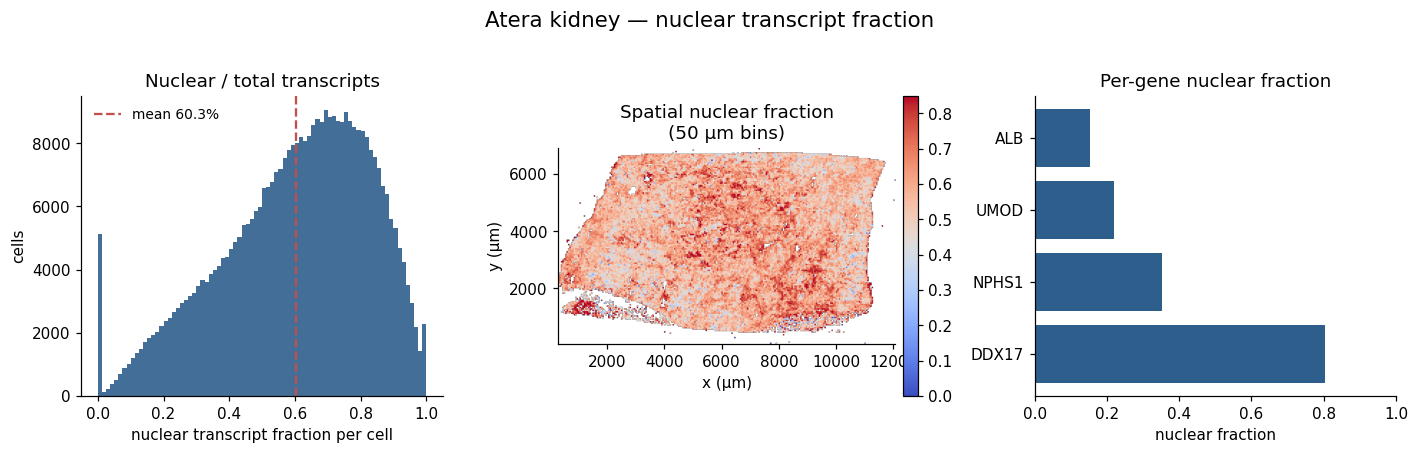

In [12]:
axes = tcl.pl.atera_nuclear_fraction(
    full,
    genes=["ALB", "UMOD", "NPHS1", "DDX17"],
    figsize=(13, 4),
    show=False,
)
axes[0].figure.suptitle("Atera kidney — nuclear transcript fraction", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


## 8. 单分子点云：指定基因 + 指定区域

`iter_atera_transcripts()` 用于大范围扫描；
`read_atera_transcripts()` 适合小区域 / 少基因查询，
并且会拒绝无过滤条件的全量读取。
指定 `genes=` 时走 `gene_offset` 快路径，只读目标基因的行区间。

In [13]:
region = (3000, 2000, 3600, 2600)
tx = tcl.io.read_atera_transcripts(
    ROI,
    genes=["UMOD", "NPHS1", "B2M", "C7", "DDX17"],
    region=region,
    min_qv=20,
)
print(f"{len(tx):,} molecules")
tx.groupby("gene", observed=True).size().to_frame("molecules")


[Atera] Streamed 28 transcript tiles in 1.0s (2 background tile(s) skipped)
28,431 molecules


,molecules
gene,
B2M,6689
C7,5450
DDX17,6017
NPHS1,789
UMOD,9486


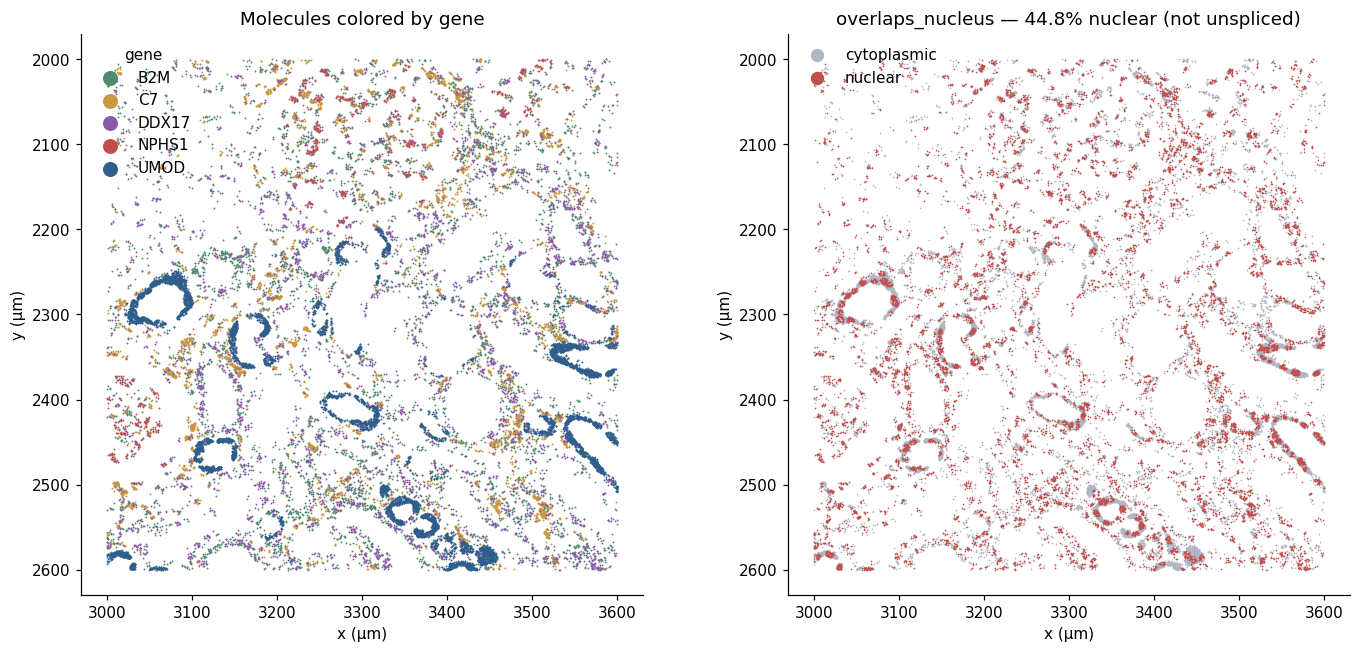

In [14]:
colors = {
    "UMOD": "#2E5E8C", "NPHS1": "#C0504D", "B2M": "#4E8A6B",
    "C7": "#C9973F", "DDX17": "#8C5AA8",
}

fig, axes = plt.subplots(1, 2, figsize=(13, 6))

ax = axes[0]
for gene, sub in tx.groupby("gene", observed=True):
    ax.scatter(
        sub["x"], sub["y"], s=1.5, linewidths=0,
        color=colors.get(str(gene), "#7F7F7F"), label=str(gene),
    )
ax.set_title("Molecules colored by gene")
ax.legend(markerscale=8, frameon=False, title="gene")

ax = axes[1]
nuclear = tx["overlaps_nucleus"].to_numpy(dtype=bool)
ax.scatter(tx.loc[~nuclear, "x"], tx.loc[~nuclear, "y"],
           s=1.2, linewidths=0, color="#B0B7C3", label="cytoplasmic")
ax.scatter(tx.loc[nuclear, "x"], tx.loc[nuclear, "y"],
           s=1.2, linewidths=0, color="#C0504D", label="nuclear")
ax.set_title(
    f"overlaps_nucleus — {nuclear.mean() * 100:.1f}% nuclear "
    "(not unspliced)"
)
ax.legend(markerscale=8, frameon=False)

for ax in axes:
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.set_xlabel("x (µm)")
    ax.set_ylabel("y (µm)")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


## 9. Preview bundle：同一套 API

Atera 早期的 preview 数据是 Xenium-v4 兼容格式
（`cell_feature_matrix.h5` + `cells.parquet`）。
`read_atera()` 会自动识别，返回同样的 schema。

In [15]:
prev = tcl.io.read_atera(
    PREVIEW,
    build_polygons=False,
    region=(0, 0, 2000, 2000),
    verbose=False,
)
print("format :", prev.uns["atera"]["format"])
print("sample :", prev.uns["atera"]["sample"])
print("shape  :", prev.shape)

format : preview
sample : WTA Cervical Cancer (FFPE)
shape  : (36863, 27104)


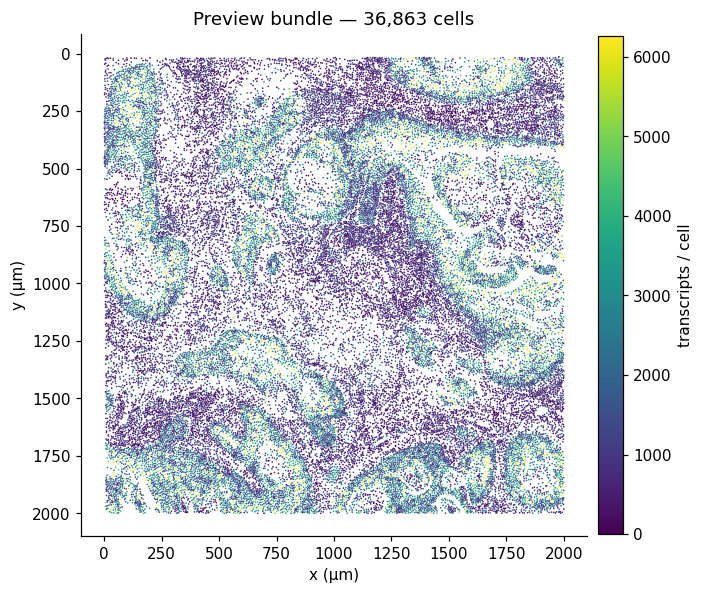

In [16]:
xy = np.asarray(prev.obsm["spatial"])
counts = pd.to_numeric(prev.obs["transcript_counts"], errors="coerce").to_numpy()

fig, ax = plt.subplots(figsize=(6.5, 6.5))
sc = ax.scatter(
    xy[:, 0], xy[:, 1], c=counts, s=1.2, cmap="viridis",
    linewidths=0, vmax=np.nanpercentile(counts, 99),
)
ax.set_aspect("equal")
ax.invert_yaxis()
ax.set_xlabel("x (µm)")
ax.set_ylabel("y (µm)")
ax.set_title(f"Preview bundle — {prev.n_obs:,} cells")
fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.02, label="transcripts / cell")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 总结

* **official Zarr**：`anndata.read_zarr(ZipStore)` 直读，不落盘解压；
  `cells.zarr` 提供细胞/核多边形。
* **坐标**：`obsm['spatial']` 始终是 µm；不要乘 `pixel_size`。
* **转录本点云**：11.9 亿分子必须流式读；`genes=` 走基因区间快路径，
  单基因查询约 1 秒。
* **QC**：Q-score、assignment rate、核质比、密度都可写回 `adata`，
  绘图函数只读 `adata`，可重复调用。
* **不支持**：isoform、splice junction、spliced/unspliced、RNA velocity。
  Atera 是 gene-level 数据，`overlaps_nucleus` 不是 unspliced。
* **多客户/多 ROI**：用 `list_atera_rois` / `iter_atera_rois` / `concat_atera_rois`，
  合并时必须显式提供 µm 偏移。

更多细节见 [Atera 使用文档](https://trackcell.readthedocs.io/en/latest/usage/atera.html)。